# Avaliação do algoritmo K-Means em uma tarefa de agrupamento não supervisionado

**Disciplina:** Aprendizado de Máquina — PPGCC / UFPI  
**Base de apoio:** MultiTarget Bioactivity ChEMBL — `chembl_activities.csv`

---

## Objetivo

Avaliar experimentalmente o comportamento do algoritmo de aprendizagem não supervisionada
**K-Means** sobre a mesma base de bioatividade utilizada no experimento anterior com SVM,
seguindo a proposta de **retirar o atributo alvo (`protein`) antes do treinamento** e verificar,
ao final, o quanto os agrupamentos descobertos apenas pela estrutura química das moléculas
correspondem às classes originais.

Neste notebook inicial, investigamos:

1. **Pré-processamento padronizado** (idêntico ao trabalho de SVM: deduplicação, remoção de
   moléculas multi-alvo, subamostragem estratificada opcional e *fingerprints* ECFP4 de 1024 bits);
2. **Escolha do número de clusters ($k$)** por métricas puramente internas (Método do Cotovelo /
   Inércia, Silhueta, Calinski-Harabasz e Davies-Bouldin);
3. **Agrupamento com $k = 4$** (número de classes originais) e **avaliação pós-treino** contra o
   atributo alvo removido (ARI, NMI, V-Measure, Pureza, matriz de contingência e alinhamento ótimo);
4. **Visualização em 2D (PCA)** comparando clusters encontrados vs. classes reais;
5. **Impacto da representação dos dados** no K-Means (ECFP4 bruto, `StandardScaler`, normalização
   L2 / K-Means esférico e redução de dimensionalidade com PCA).

> A base de bioatividade é o **instrumento** do experimento. As conclusões do trabalho
> são sobre o **algoritmo K-Means**, não sobre química ou farmacologia.

## Formulação da tarefa

| Item | Descrição |
|---|---|
| Entrada ($X$) | Estrutura química de uma molécula (SMILES $\rightarrow$ *fingerprint* ECFP4, 1024 bits) |
| Atributo removido | `protein` (BACE1, DRD2, EGFR, HDAC1) — **não utilizado no treinamento** |
| Saída do K-Means | Rótulo de cluster atribuído de forma não supervisionada ($0, 1, \dots, k-1$) |
| Avaliação pós-treino | Comparação dos clusters obtidos com as 4 classes originais removidas |

## 1. Configuração do ambiente

In [1]:
try:
    import rdkit
except ImportError:
    %pip install -q rdkit

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "font.size": 10})

OUT = "resultados"
os.makedirs(OUT, exist_ok=True)

print("Ambiente configurado.")

Ambiente configurado.


## 2. Carga da base

A detecção do arquivo é automática: procura na pasta `data/` local, na pasta do projeto de SVM
ou no ambiente Colab. Caso não seja encontrado no Colab, a janela de upload será aberta automaticamente.

In [3]:
# Busca automática do arquivo em diretórios locais ou Google Colab
possiveis_caminhos = [
    "data/chembl_activities.csv",
    "data/chembl_activities (1).csv",
    "chembl_activities.csv",
    "chembl_activities (1).csv",
    "PPGCC_ML_KMeans/data/chembl_activities.csv",
    "../PPGCC_ML_SVG/data/chembl_activities (1).csv",
    "PPGCC_ML_SVG/data/chembl_activities (1).csv",
    "../data/chembl_activities.csv",
    "../data/chembl_activities (1).csv",
    "/content/chembl_activities.csv",
    "/content/chembl_activities (1).csv",
]

CAMINHO = None
for p in possiveis_caminhos:
    if os.path.exists(p):
        CAMINHO = p
        break

# Se não encontrado localmente, tenta upload no Google Colab
if CAMINHO is None:
    try:
        from google.colab import files
        print("Arquivo local não encontrado. Selecione o arquivo chembl_activities.csv para upload:")
        enviados = files.upload()
        if enviados:
            CAMINHO = list(enviados.keys())[0]
    except Exception as e:
        print("Upload do Colab não disponível:", e)

if CAMINHO is None or not os.path.exists(CAMINHO):
    raise FileNotFoundError(
        "Arquivo de dados não encontrado! "
        "Coloque chembl_activities.csv na pasta data/ ou realize o upload no Colab."
    )

print("Arquivo carregado com sucesso:", os.path.abspath(CAMINHO))

Arquivo carregado com sucesso: C:\Users\cabra\OneDrive\Imagens\Documentos\Projetos\ML\PPGCC_UFPI_Machine_Learning\PPGCC_ML_KMeans\data\chembl_activities.csv


In [4]:
df_bruto = pd.read_csv(CAMINHO, low_memory=False)

print(f"Dimensões: {df_bruto.shape[0]:,} linhas x {df_bruto.shape[1]} colunas\n")
df_bruto.head()

Dimensões: 58,736 linhas x 14 colunas



,protein,activity_id,molecule_chembl_id,canonical_smiles,target_chembl_id,assay_chembl_id,assay_type,standard_type,standard_relation,standard_value,standard_units,pchembl_value,data_validity_comment,potential_duplicate
0,EGFR,32260,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,CHEMBL203,CHEMBL674637,B,IC50,=,41.0,nM,7.39,NaN,0
1,EGFR,32267,CHEMBL69960,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...,CHEMBL203,CHEMBL674637,B,IC50,=,170.0,nM,6.77,NaN,0
2,EGFR,32680,CHEMBL137635,CN(c1ccccc1)c1ncnc2ccc(N/N=N/Cc3ccccn3)cc12,CHEMBL203,CHEMBL677833,B,IC50,=,9300.0,nM,5.03,NaN,0
3,EGFR,32780,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL674643,B,IC50,=,96000.0,nM,4.02,NaN,0
4,EGFR,32781,CHEMBL77085,N#CC(C#N)=Cc1cc(O)ccc1[N+](=O)[O-],CHEMBL203,CHEMBL675636,B,Ki,=,24000.0,nM,4.62,NaN,0


## 3. Caracterização rápida da base

Assim como observado no experimento de SVM, **cada linha representa uma medição experimental**,
não uma molécula única. A deduplicação continua indispensável no agrupamento não supervisionado:
se a mesma molécula aparecesse várias vezes na matriz $X$, ela teria peso artificialmente maior no
cálculo dos centróides do K-Means, distorcendo os clusters.

In [5]:
print(f"Registros de atividade : {len(df_bruto):,}")
print(f"Moléculas únicas       : {df_bruto['molecule_chembl_id'].nunique():,}")
print(f"Medições por molécula  : {len(df_bruto) / df_bruto['molecule_chembl_id'].nunique():.2f}")
print("\nDistribuição original por proteína (atributo que será removido no treino):")
print(df_bruto["protein"].value_counts().to_string())

Registros de atividade : 58,736
Moléculas únicas       : 37,515
Medições por molécula  : 1.57

Distribuição original por proteína (atributo que será removido no treino):
protein
EGFR     19866
BACE1    15698
DRD2     12816
HDAC1    10356


## 4. Pré-processamento (idêntico ao SVM) e remoção do atributo alvo

Mantemos exatamente o mesmo pré-processamento do experimento com SVM para garantir comparabilidade
entre os trabalhos:

| Passo | Ação | Justificativa |
|---|---|---|
| 1 | Agrupar por `(molécula, alvo)`, tomando a mediana do `pchembl_value` | Elimina réplicas experimentais para não enviesar os centróides |
| 2 | Remover moléculas ligadas a mais de um alvo | Garante referência pós-treino com classes mutuamente exclusivas |
| 3 | Subamostragem estratificada (`N_MAX = 8000` ou `None`) | Mantém a mesma amostra do SVM e garante execução rápida |
| 4 | Converter SMILES em *fingerprint* **ECFP4** (1024 bits, raio 2) | Representação numérica fixa exigida pelo K-Means |
| 5 | **Retirar o atributo alvo (`protein`)** | O K-Means recebe **apenas** $X$; `y_real` fica reservado apenas para análise pós-treino |

In [6]:
# Passo 1 — deduplicação por (molécula, alvo)
dados = (
    df_bruto
    .dropna(subset=["canonical_smiles"])
    .groupby(["molecule_chembl_id", "protein"], as_index=False)
    .agg(
        smiles=("canonical_smiles", "first"),
        pchembl=("pchembl_value", "median"),
        n_medicoes=("activity_id", "count"),
    )
)

print(f"Após deduplicação: {len(dados):,} pares (molécula, alvo)")

# Passo 2 — apenas moléculas de alvo único
n_alvos = dados.groupby("molecule_chembl_id")["protein"].nunique()
dados = dados[dados.molecule_chembl_id.isin(n_alvos[n_alvos == 1].index)].reset_index(drop=True)

print(f"Após remover multi-alvo: {len(dados):,} moléculas\n")
print(dados["protein"].value_counts().to_string())

Após deduplicação: 37,547 pares (molécula, alvo)


Após remover multi-alvo: 37,404 moléculas

protein
EGFR     10674
BACE1    10016
DRD2      8659
HDAC1     8055


In [7]:
# Passo 3 — subamostragem estratificada (mesmo padrão do SVM; use None para base completa)
from sklearn.model_selection import train_test_split

N_MAX = 8000  # Coloque None para executar na base completa (~37 mil moléculas)

if N_MAX is not None and len(dados) > N_MAX:
    idx, _ = train_test_split(
        np.arange(len(dados)),
        train_size=N_MAX,
        stratify=dados["protein"],
        random_state=RANDOM_STATE,
    )
    dados = dados.iloc[idx].reset_index(drop=True)
    print(f"Subamostra estratificada: {len(dados):,} moléculas")
else:
    print(f"Base completa: {len(dados):,} moléculas")

print(dados["protein"].value_counts().to_string())

Subamostra estratificada: 8,000 moléculas
protein
EGFR     2283
BACE1    2142
DRD2     1852
HDAC1    1723


In [8]:
# Passo 4 — geração dos fingerprints ECFP4 (1024 bits, raio 2)
from rdkit import Chem, RDLogger
from rdkit.Chem import rdFingerprintGenerator

RDLogger.DisableLog("rdApp.*")

N_BITS, RAIO = 1024, 2
gerador = rdFingerprintGenerator.GetMorganGenerator(radius=RAIO, fpSize=N_BITS)

t0 = time.time()
vetores, validos = [], []
for i, smi in enumerate(dados["smiles"]):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        continue
    vetores.append(np.array(gerador.GetFingerprint(mol), dtype=np.uint8))
    validos.append(i)

n_invalidos = len(dados) - len(validos)
X = np.vstack(vetores).astype(np.float32)
dados = dados.iloc[validos].reset_index(drop=True)

print(f"Fingerprints gerados em {time.time() - t0:.1f}s")
print(f"Matriz de atributos X: {X.shape} (dtype={X.dtype})")
print(f"SMILES inválidos descartados: {n_invalidos}")
print(f"Esparsidade: {(X == 0).mean():.1%} dos bits são zero")
print(f"Bits ativos por molécula (média): {X.sum(axis=1).mean():.1f} de {N_BITS}")

Fingerprints gerados em 13.0s
Matriz de atributos X: (8000, 1024) (dtype=float32)
SMILES inválidos descartados: 0
Esparsidade: 94.4% dos bits são zero
Bits ativos por molécula (média): 56.9 de 1024


In [9]:
# Passo 5 — remoção explícita do atributo classe (protein)
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_real = le.fit_transform(dados["protein"])
CLASSES = le.classes_
N_CLASSES = len(CLASSES)

# Matriz sem rótulo que será utilizada pelo K-Means
X_sem_alvo = X.copy()

print("Atributo 'protein' removido dos dados de entrada do modelo.")
print(f"Entrada do K-Means (X_sem_alvo): {X_sem_alvo.shape}")
print(f"Referência pós-treino (y_real) : {y_real.shape} -> {dict(enumerate(CLASSES))}")

Atributo 'protein' removido dos dados de entrada do modelo.
Entrada do K-Means (X_sem_alvo): (8000, 1024)
Referência pós-treino (y_real) : (8000,) -> {0: 'BACE1', 1: 'DRD2', 2: 'EGFR', 3: 'HDAC1'}


## 5. Experimento A — Escolha do número de clusters ($k$)

Em um cenário estritamente não supervisionado, não conhecemos de antemão o número real de classes.
Por isso, avaliamos valores de $k \in \{2, 3, \dots, 10\}$ utilizando **métricas internas**
(que dependem apenas de $X$ e dos rótulos de cluster, sem usar `y_real`):

| Métrica interna | O que mede | Direção desejável |
|---|---|---|
| **Inércia (WCSS / SSE)** | Soma das distâncias quadráticas de cada ponto ao seu centróide | Menor (buscar o "cotovelo") |
| **Silhueta (Silhouette)** | Coesão intra-cluster vs. separação inter-cluster ($[-1, 1]$) | Maior |
| **Calinski-Harabasz** | Razão entre dispersão inter-cluster e intra-cluster | Maior |
| **Davies-Bouldin** | Similaridade média entre cada cluster e seu vizinho mais próximo | Menor |

> **Nota prática:** Para o coeficiente de Silhueta, usamos `sample_size=min(len(X), 5000)` para
> manter o custo computacional viável mesmo se `N_MAX = None` for utilizado.

In [10]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
)

VALORES_K = list(range(2, 11))
SIL_SAMPLE = min(len(X_sem_alvo), 5000)

registros_k = []
for k in VALORES_K:
    t0 = time.time()
    km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
    rotulos = km.fit_predict(X_sem_alvo)
    dur = time.time() - t0

    sil = silhouette_score(
        X_sem_alvo, rotulos, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE
    )
    ch = calinski_harabasz_score(X_sem_alvo, rotulos)
    db = davies_bouldin_score(X_sem_alvo, rotulos)

    registros_k.append({
        "k": k,
        "inercia": float(km.inertia_),
        "silhueta": float(sil),
        "calinski_harabasz": float(ch),
        "davies_bouldin": float(db),
        "n_iter": int(km.n_iter_),
        "tempo_s": float(dur),
    })
    print(
        f"k={k:2d} | Inércia={km.inertia_:10.1f} | Silhueta={sil:.4f} | "
        f"CH={ch:7.1f} | DB={db:.3f} | {dur:.1f}s"
    )

res_k = pd.DataFrame(registros_k)
res_k.to_csv(f"{OUT}/experimento_k.csv", index=False)

k= 2 | Inércia=  335262.3 | Silhueta=0.0360 | CH=  234.7 | DB=5.678 | 15.7s


k= 3 | Inércia=  326508.9 | Silhueta=0.0433 | CH=  227.7 | DB=4.544 | 3.1s


k= 4 | Inércia=  320119.1 | Silhueta=0.0339 | CH=  208.0 | DB=4.846 | 3.2s


k= 5 | Inércia=  314112.6 | Silhueta=0.0428 | CH=  197.2 | DB=4.227 | 3.5s


k= 6 | Inércia=  310875.6 | Silhueta=0.0404 | CH=  176.0 | DB=4.328 | 12.9s


k= 7 | Inércia=  305241.1 | Silhueta=0.0488 | CH=  174.0 | DB=3.916 | 62.3s


k= 8 | Inércia=  301322.2 | Silhueta=0.0511 | CH=  165.9 | DB=3.853 | 54.9s


k= 9 | Inércia=  298223.2 | Silhueta=0.0513 | CH=  157.0 | DB=4.112 | 38.6s


k=10 | Inércia=  295711.9 | Silhueta=0.0470 | CH=  148.3 | DB=4.173 | 8.7s


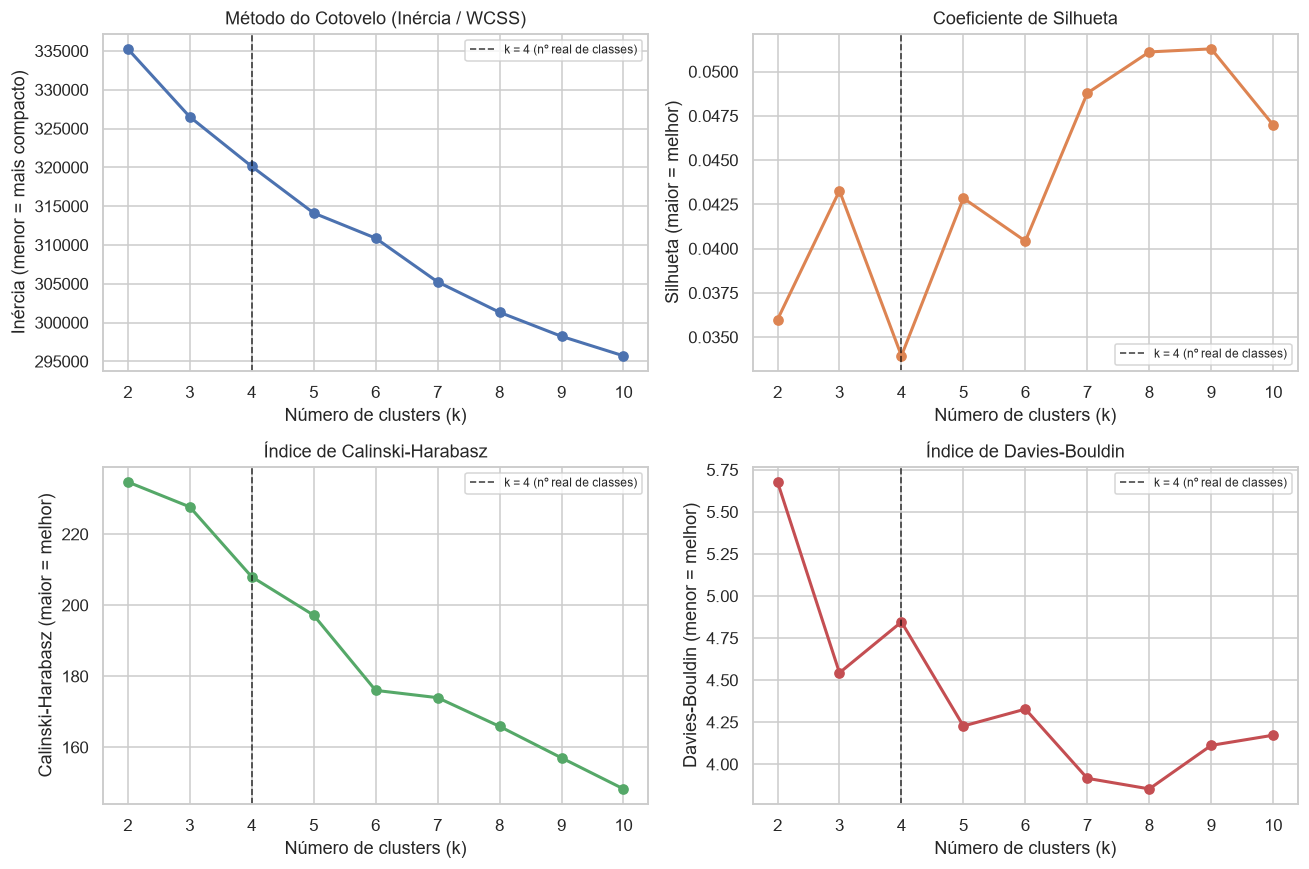

Melhor k segundo a Silhueta: k = 9


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

metricas_plot = [
    ("inercia", "Método do Cotovelo (Inércia / WCSS)", "Inércia (menor = mais compacto)", "#4C72B0"),
    ("silhueta", "Coeficiente de Silhueta", "Silhueta (maior = melhor)", "#DD8452"),
    ("calinski_harabasz", "Índice de Calinski-Harabasz", "Calinski-Harabasz (maior = melhor)", "#55A868"),
    ("davies_bouldin", "Índice de Davies-Bouldin", "Davies-Bouldin (menor = melhor)", "#C44E52"),
]

for ax, (col, titulo, ylabel, cor) in zip(axes.ravel(), metricas_plot):
    ax.plot(res_k["k"], res_k[col], "o-", color=cor, linewidth=2, markersize=6)
    ax.axvline(N_CLASSES, color="black", ls="--", lw=1.1, alpha=0.7, label=f"k = {N_CLASSES} (nº real de classes)")
    ax.set_title(titulo)
    ax.set_xlabel("Número de clusters (k)")
    ax.set_ylabel(ylabel)
    ax.set_xticks(VALORES_K)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUT}/experimento_k.png", bbox_inches="tight")
plt.show()

melhor_k_sil = int(res_k.loc[res_k["silhueta"].idxmax(), "k"])
print(f"Melhor k segundo a Silhueta: k = {melhor_k_sil}")

## 6. Experimento B — Treinamento do K-Means com $k = 4$ e avaliação pós-treino

Seguindo diretamente a sugestão do professor, treinamos o K-Means com **$k = 4$** (correspondente
aos 4 alvos proteicos originais) **sem fornecer os rótulos**, e só depois comparamos os clusters
formados com o atributo alvo removido (`y_real`).

Como os números dos clusters ($0, 1, 2, 3$) são arbitrários, utilizamos métricas **externas**
invariantes à permutação de rótulos:

- **ARI (Adjusted Rand Index):** mede concordância entre partições descontando o acaso ($0$ = aleatório, $1$ = perfeito);
- **NMI (Normalized Mutual Information):** informação mútua normalizada entre clusters e classes reais ($[0, 1]$);
- **Homogeneidade, Completude e V-Measure:** avaliam se cada cluster contém majoritariamente uma única classe (homogeneidade) e se membros de uma mesma classe ficam no mesmo cluster (completude);
- **Pureza (Purity):** fração de amostras pertencentes à classe majoritária de cada cluster;
- **Alinhamento ótimo (Algoritmo Húngaro):** associa cada cluster a uma classe distinta de forma a maximizar o acerto global, permitindo calcular uma acurácia/F1-macro comparável ao SVM supervisionado.

In [12]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    accuracy_score,
    f1_score,
)


def pureza_clusters(y_true, y_pred):
    cont = pd.crosstab(y_pred, y_true)
    return float(cont.max(axis=1).sum() / len(y_true))


def alinhar_clusters_hungaro(y_true, y_pred):
    '''Mapeia cada cluster para a classe real ótima via Algoritmo Húngaro.'''
    cont = pd.crosstab(y_pred, y_true).values
    linhas, colunas = linear_sum_assignment(-cont)
    mapa = {int(c_cluster): int(c_classe) for c_cluster, c_classe in zip(linhas, colunas)}
    y_alinhado = np.array([mapa[c] for c in y_pred])
    return y_alinhado, mapa


def avaliar_agrupamento(X_mat, y_true, clusters):
    y_alinhado, mapa = alinhar_clusters_hungaro(y_true, clusters)
    return {
        "silhueta": float(silhouette_score(X_mat, clusters, sample_size=min(len(X_mat), 5000), random_state=RANDOM_STATE)),
        "davies_bouldin": float(davies_bouldin_score(X_mat, clusters)),
        "ari": float(adjusted_rand_score(y_true, clusters)),
        "nmi": float(normalized_mutual_info_score(y_true, clusters)),
        "homogeneidade": float(homogeneity_score(y_true, clusters)),
        "completude": float(completeness_score(y_true, clusters)),
        "v_measure": float(v_measure_score(y_true, clusters)),
        "pureza": pureza_clusters(y_true, clusters),
        "acuracia_alinhada": float(accuracy_score(y_true, y_alinhado)),
        "f1_macro_alinhado": float(f1_score(y_true, y_alinhado, average="macro")),
    }, y_alinhado, mapa


t0 = time.time()
km_k4 = KMeans(n_clusters=N_CLASSES, init="k-means++", n_init=20, random_state=RANDOM_STATE)
clusters_k4 = km_k4.fit_predict(X_sem_alvo)
tempo_k4 = time.time() - t0

metricas_k4, y_alinhado_k4, mapa_k4 = avaliar_agrupamento(X_sem_alvo, y_real, clusters_k4)

print(f"K-Means (k={N_CLASSES}) treinado em {tempo_k4:.2f}s ({km_k4.n_iter_} iterações)\n")
print("MÉTRICAS DE AVALIAÇÃO (k = 4, ECFP4 bruto)")
print("=" * 50)
for nome, valor in metricas_k4.items():
    print(f"  {nome:22s}: {valor:.4f}")

print("\nMapeamento ótimo (Cluster -> Proteína):")
for c_id, cls_id in sorted(mapa_k4.items()):
    print(f"  Cluster {c_id} -> {CLASSES[cls_id]}")

K-Means (k=4) treinado em 7.01s (39 iterações)

MÉTRICAS DE AVALIAÇÃO (k = 4, ECFP4 bruto)
  silhueta              : 0.0339
  davies_bouldin        : 4.8456
  ari                   : 0.4754
  nmi                   : 0.5403
  homogeneidade         : 0.5324
  completude            : 0.5485
  v_measure             : 0.5403
  pureza                : 0.7710
  acuracia_alinhada     : 0.7710
  f1_macro_alinhado     : 0.7766

Mapeamento ótimo (Cluster -> Proteína):
  Cluster 0 -> HDAC1
  Cluster 1 -> BACE1
  Cluster 2 -> DRD2
  Cluster 3 -> EGFR


Contagem absoluta (Cluster x Proteína Real):
Proteína Real      BACE1  DRD2  EGFR  HDAC1
Cluster (K-Means)                          
0                    632   210   572   1611
1                   1389     3    15      5
2                    116  1638   166     78
3                      5     1  1530     29

Proporção por cluster (linhas somam 100%):
Proteína Real      BACE1  DRD2  EGFR  HDAC1
Cluster (K-Means)                          
0                   20.9   6.9  18.9   53.3
1                   98.4   0.2   1.1    0.4
2                    5.8  82.0   8.3    3.9
3                    0.3   0.1  97.8    1.9


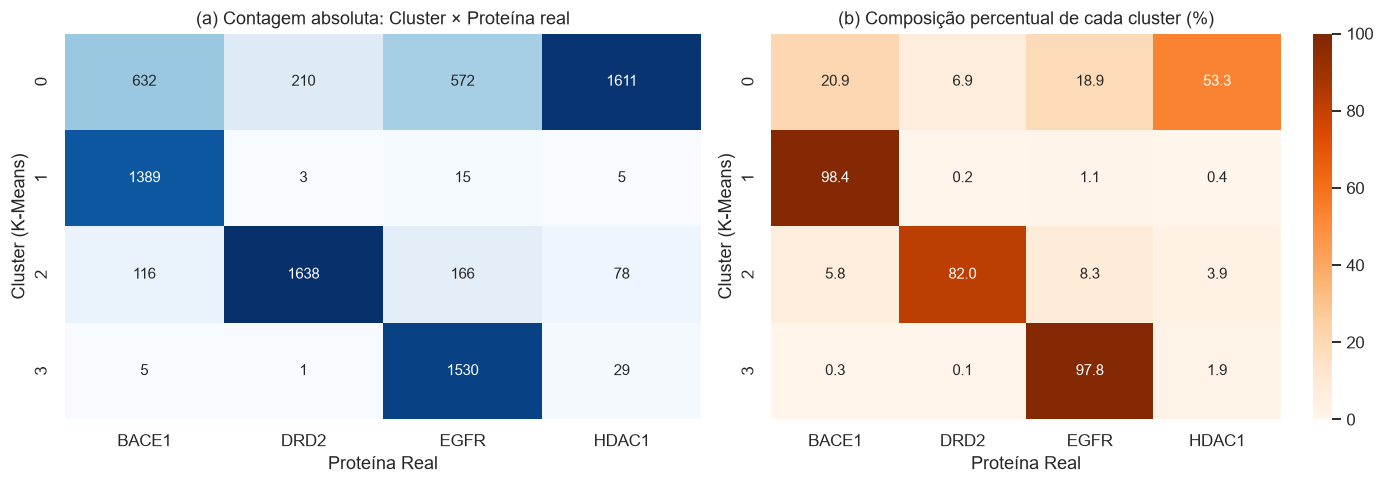

In [13]:
# Tabela de contingência: Clusters encontrados x Classes reais removidas
cont_abs = pd.crosstab(
    pd.Series(clusters_k4, name="Cluster (K-Means)"),
    pd.Series(dados["protein"], name="Proteína Real"),
)
cont_prop = cont_abs.div(cont_abs.sum(axis=1), axis=0)

print("Contagem absoluta (Cluster x Proteína Real):")
print(cont_abs.to_string())
print("\nProporção por cluster (linhas somam 100%):")
print((cont_prop * 100).round(1).to_string())

cont_abs.to_csv(f"{OUT}/matriz_contingencia_k4.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.heatmap(cont_abs, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar=False)
axes[0].set_title("(a) Contagem absoluta: Cluster × Proteína real")

sns.heatmap(cont_prop * 100, annot=True, fmt=".1f", cmap="Oranges", ax=axes[1], vmin=0, vmax=100)
axes[1].set_title("(b) Composição percentual de cada cluster (%)")

plt.tight_layout()
plt.savefig(f"{OUT}/matriz_contingencia_k4.png", bbox_inches="tight")
plt.show()

## 7. Visualização dos agrupamentos em 2D (PCA)

Como o espaço original possui 1024 dimensões, projetamos as moléculas nos **2 primeiros
componentes principais (PCA)** para inspecionar visualmente:

- **(a)** Como o K-Means particionou o espaço;
- **(b)** Onde estão distribuídas as 4 classes reais que foram removidas do treino.

Também verificamos a variância explicada acumulada pelo PCA para avaliar o grau de dispersão
dos *fingerprints* em alta dimensionalidade.

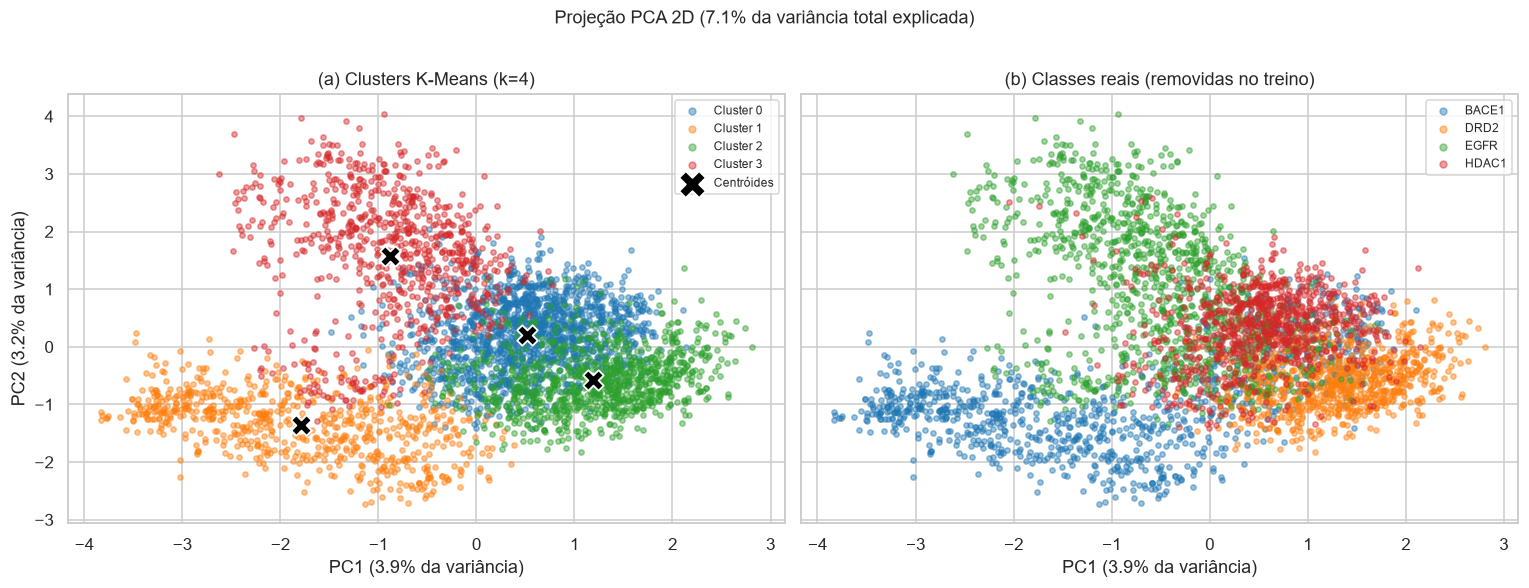

In [14]:
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_2d = pca_2d.fit_transform(X_sem_alvo)
centroides_2d = pca_2d.transform(km_k4.cluster_centers_)
var_2d = pca_2d.explained_variance_ratio_

# Amostra para visualização mais limpa caso a base seja muito grande
N_PLOT = min(len(X_2d), 4000)
rng = np.random.default_rng(RANDOM_STATE)
idx_plot = rng.choice(len(X_2d), size=N_PLOT, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)

paleta = sns.color_palette("tab10", N_CLASSES)

# (a) Clusters K-Means
for c in range(N_CLASSES):
    m = clusters_k4[idx_plot] == c
    axes[0].scatter(
        X_2d[idx_plot[m], 0], X_2d[idx_plot[m], 1],
        s=12, alpha=0.45, color=paleta[c], label=f"Cluster {c}",
    )
axes[0].scatter(
    centroides_2d[:, 0], centroides_2d[:, 1],
    s=180, c="black", marker="X", edgecolor="white", linewidth=1.2, label="Centróides",
)
axes[0].set_title(f"(a) Clusters K-Means (k={N_CLASSES})")
axes[0].set_xlabel(f"PC1 ({var_2d[0]:.1%} da variância)")
axes[0].set_ylabel(f"PC2 ({var_2d[1]:.1%} da variância)")
axes[0].legend(fontsize=8, markerscale=1.3)

# (b) Classes reais removidas
for i, nome_cls in enumerate(CLASSES):
    m = y_real[idx_plot] == i
    axes[1].scatter(
        X_2d[idx_plot[m], 0], X_2d[idx_plot[m], 1],
        s=12, alpha=0.45, color=paleta[i], label=str(nome_cls),
    )
axes[1].set_title("(b) Classes reais (removidas no treino)")
axes[1].set_xlabel(f"PC1 ({var_2d[0]:.1%} da variância)")
axes[1].legend(fontsize=8, markerscale=1.3)

plt.suptitle(
    f"Projeção PCA 2D ({var_2d.sum():.1%} da variância total explicada)",
    fontsize=12, y=1.02,
)
plt.tight_layout()
plt.savefig(f"{OUT}/visualizacao_pca_2d.png", bbox_inches="tight")
plt.show()

## 8. Experimento C — Impacto da representação e pré-processamento no K-Means

O K-Means tradicional minimiza a **distância euclidiana** em todas as dimensões simultaneamente.
Em dados binários esparsos de alta dimensionalidade (1024 bits, ~95% zeros), a distância euclidiana
sofre com a **maldição da dimensionalidade** e com diferenças no número de bits ativos por molécula.

Para investigar o comportamento do algoritmo, comparamos 4 representações para $k = 4$:

1. **ECFP4 bruto (0/1):** linha de base direta do pré-processamento do SVM;
2. **ECFP4 + `StandardScaler`:** padronização z-score por bit (amplifica bits raros);
3. **ECFP4 + Normalização L2 (`Normalizer`):** projeta os vetores na esfera unitária, tornando o
   K-Means equivalente ao **K-Means esférico** (otimizando similaridade de cosseno);
4. **ECFP4 + PCA (50 componentes):** reduz ruído e dimensionalidade antes do agrupamento.

In [15]:
from sklearn.preprocessing import StandardScaler, Normalizer

X_std = StandardScaler().fit_transform(X_sem_alvo)
X_l2 = Normalizer(norm="l2").fit_transform(X_sem_alvo)

pca_50 = PCA(n_components=50, random_state=RANDOM_STATE)
X_pca50 = pca_50.fit_transform(X_sem_alvo)
print(f"PCA (50 componentes) explica {pca_50.explained_variance_ratio_.sum():.1%} da variância.\n")

cenarios = {
    "ECFP4 bruto (0/1)": X_sem_alvo,
    "ECFP4 + StandardScaler": X_std,
    "ECFP4 + Normalização L2": X_l2,
    "ECFP4 + PCA (50 comp.)": X_pca50,
}

linhas_rep = []
for nome, X_rep in cenarios.items():
    t0 = time.time()
    km = KMeans(n_clusters=N_CLASSES, init="k-means++", n_init=20, random_state=RANDOM_STATE)
    rot = km.fit_predict(X_rep)
    dur = time.time() - t0

    m, _, _ = avaliar_agrupamento(X_rep, y_real, rot)
    m["cenario"] = nome
    m["tempo_s"] = float(dur)
    linhas_rep.append(m)

    print(
        f"{nome:26s} | ARI={m['ari']:.4f} | NMI={m['nmi']:.4f} | "
        f"Pureza={m['pureza']:.4f} | Sil={m['silhueta']:.4f} | {dur:.2f}s"
    )

res_rep = pd.DataFrame(linhas_rep)[
    ["cenario", "ari", "nmi", "v_measure", "pureza", "acuracia_alinhada", "f1_macro_alinhado", "silhueta", "tempo_s"]
]
res_rep.to_csv(f"{OUT}/comparacao_representacoes.csv", index=False)

PCA (50 componentes) explica 47.1% da variância.



ECFP4 bruto (0/1)          | ARI=0.4754 | NMI=0.5403 | Pureza=0.7710 | Sil=0.0339 | 11.44s


ECFP4 + StandardScaler     | ARI=0.0887 | NMI=0.2732 | Pureza=0.4469 | Sil=0.0120 | 8.61s


ECFP4 + Normalização L2    | ARI=0.4923 | NMI=0.5403 | Pureza=0.7792 | Sil=0.0374 | 11.64s


ECFP4 + PCA (50 comp.)     | ARI=0.4701 | NMI=0.5363 | Pureza=0.7685 | Sil=0.0711 | 0.79s


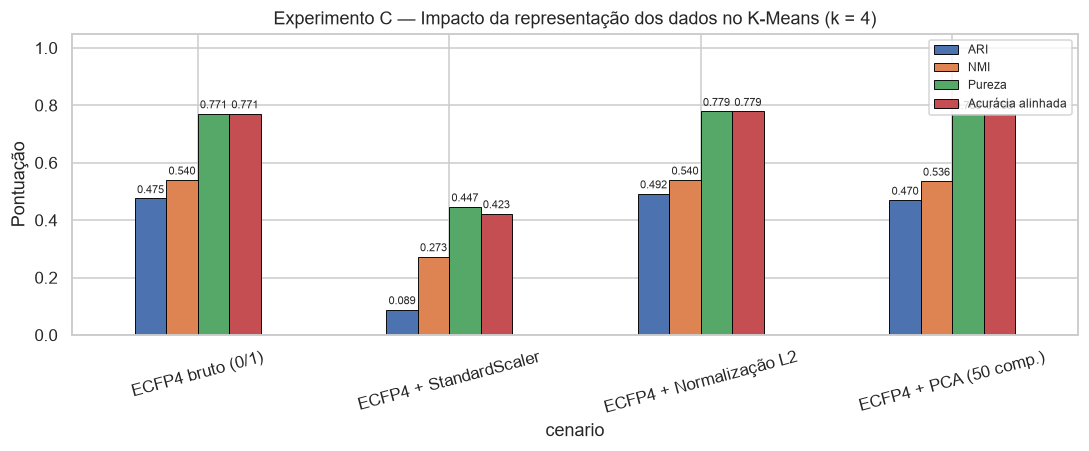

In [16]:
fig, ax = plt.subplots(figsize=(10, 4.2))
cols_plot = ["ari", "nmi", "pureza", "acuracia_alinhada"]
res_rep.set_index("cenario")[cols_plot].plot(
    kind="bar", ax=ax, edgecolor="black", linewidth=0.6
)
ax.set_title("Experimento C — Impacto da representação dos dados no K-Means (k = 4)")
ax.set_ylabel("Pontuação")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=15)
ax.legend(["ARI", "NMI", "Pureza", "Acurácia alinhada"], fontsize=8, loc="upper right")

for c in ax.containers:
    ax.bar_label(c, fmt="%.3f", fontsize=7, padding=2)

plt.tight_layout()
plt.savefig(f"{OUT}/comparacao_representacoes.png", bbox_inches="tight")
plt.show()

## 9. Resumo executivo e exportação dos resultados

In [17]:
L = "=" * 72
print(L)
print("RESUMO EXECUTIVO — K-MEANS (ChEMBL MultiTarget Bioactivity)")
print(L)
print(f"Base bruta           : {len(df_bruto):,} medições")
print(f"Base pré-processada  : {len(dados):,} moléculas únicas x {X_sem_alvo.shape[1]} atributos (ECFP4)")
print(f"Classes removidas    : {', '.join(map(str, CLASSES))} (k real = {N_CLASSES})")
print(f"Melhor k (Silhueta)  : k = {melhor_k_sil}")

print("\n[ K-MEANS k=4 — ECFP4 BRUTO ]")
print(f"  Silhueta            : {metricas_k4['silhueta']:.4f}")
print(f"  ARI                 : {metricas_k4['ari']:.4f}")
print(f"  NMI                 : {metricas_k4['nmi']:.4f}")
print(f"  V-Measure           : {metricas_k4['v_measure']:.4f}")
print(f"  Pureza              : {metricas_k4['pureza']:.4f}")
print(f"  Acurácia alinhada   : {metricas_k4['acuracia_alinhada']:.4f}")
print(f"  F1-macro alinhado   : {metricas_k4['f1_macro_alinhado']:.4f}")

print("\n[ COMPARAÇÃO DE REPRESENTAÇÕES (k=4) ]")
for _, r in res_rep.iterrows():
    print(
        f"  {r.cenario:26s} ARI={r.ari:.4f}  NMI={r.nmi:.4f}  "
        f"Pureza={r.pureza:.4f}  ({r.tempo_s:.2f}s)"
    )
print(L)

resumo = {
    "base": {
        "registros_brutos": int(len(df_bruto)),
        "moleculas": int(len(dados)),
        "n_atributos": int(X_sem_alvo.shape[1]),
        "classes_removidas": [str(c) for c in CLASSES],
    },
    "experimento_k": {
        "melhor_k_silhueta": melhor_k_sil,
        "resultados": res_k.round(4).to_dict("records"),
    },
    "kmeans_k4_bruto": {
        "metricas": {k: round(v, 4) for k, v in metricas_k4.items()},
        "mapeamento_otimo": {str(k): str(CLASSES[v]) for k, v in mapa_k4.items()},
        "tempo_s": round(tempo_k4, 3),
    },
    "comparacao_representacoes": res_rep.round(4).to_dict("records"),
}

with open(f"{OUT}/resumo.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, indent=2, ensure_ascii=False)

print("\nArquivos gerados em ./resultados/:")
for a in sorted(os.listdir(OUT)):
    print(f"  {a}")

RESUMO EXECUTIVO — K-MEANS (ChEMBL MultiTarget Bioactivity)
Base bruta           : 58,736 medições
Base pré-processada  : 8,000 moléculas únicas x 1024 atributos (ECFP4)
Classes removidas    : BACE1, DRD2, EGFR, HDAC1 (k real = 4)
Melhor k (Silhueta)  : k = 9

[ K-MEANS k=4 — ECFP4 BRUTO ]
  Silhueta            : 0.0339
  ARI                 : 0.4754
  NMI                 : 0.5403
  V-Measure           : 0.5403
  Pureza              : 0.7710
  Acurácia alinhada   : 0.7710
  F1-macro alinhado   : 0.7766

[ COMPARAÇÃO DE REPRESENTAÇÕES (k=4) ]
  ECFP4 bruto (0/1)          ARI=0.4754  NMI=0.5403  Pureza=0.7710  (11.44s)
  ECFP4 + StandardScaler     ARI=0.0887  NMI=0.2732  Pureza=0.4469  (8.61s)
  ECFP4 + Normalização L2    ARI=0.4923  NMI=0.5403  Pureza=0.7792  (11.64s)
  ECFP4 + PCA (50 comp.)     ARI=0.4701  NMI=0.5363  Pureza=0.7685  (0.79s)

Arquivos gerados em ./resultados/:
  comparacao_representacoes.csv
  comparacao_representacoes.png
  experimento_k.csv
  experimento_k.png
  matr

In [18]:
# Compactação dos resultados (compatível com Windows, Linux e Colab)
import shutil

shutil.make_archive("resultados", "zip", OUT)
print("Resultados compactados com sucesso em resultados.zip")

try:
    from google.colab import files
    files.download("resultados.zip")
except Exception:
    print("Fora do Colab — arquivo disponível em ./resultados.zip")

Resultados compactados com sucesso em resultados.zip
Fora do Colab — arquivo disponível em ./resultados.zip


---

## 10. Conclusões iniciais e próximos passos

*Após executar o notebook, preencha os valores observados e discuta os pontos abaixo:*

1. **Escolha de $k$ sem supervisão:** O método do cotovelo e a silhueta apontaram $k = 4$ ou um
   valor diferente? Em espaços de alta dimensionalidade (1024 bits), valores de silhueta tendem a
   ser numericamente baixos mesmo quando há estrutura nos dados.
2. **Recuperação das classes originais ($k = 4$):** Pela matriz de contingência, ARI e NMI, quais
   proteínas formaram clusters mais puros e quais se misturaram? Comparar a acurácia/F1 alinhada
   do K-Means com o resultado supervisionado do SVM evidencia o papel da supervisão na separação
   de fronteiras complexas.
3. **Efeito da representação:** Comparar `ECFP4 bruto`, `StandardScaler`, `Normalização L2` e
   `PCA (50)` mostra como a métrica de distância euclidiana do K-Means reage a vetores esparsos.
4. **Possíveis extensões para o relatório final:**
   - Investigar a sensibilidade à inicialização (`init='k-means++'` vs. `init='random'`) e múltiplas sementes;
   - Avaliar $k > 4$ (subclusters estruturais dentro de cada proteína);
   - Testar descritores físico-químicos (como na contraprova do SVM) com e sem `StandardScaler`;
   - Comparar o K-Means com outro método não supervisionado (ex.: Agrupamento Hierárquico / DBSCAN / MiniBatchKMeans).